# Notebook 5: Retention Analysis
**Business question:** Does a customer's first-order experience (delivery and review) affect whether they come back? And how does retention look over time?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid")
IMAGES = Path("../images")
PROCESSED = Path("../data/processed")

master = pd.read_csv(PROCESSED / "orders_master.csv", parse_dates=["order_purchase_timestamp"])
master = master.dropna(subset=["payment_value"]).sort_values("order_purchase_timestamp")
print("Orders:", len(master))

Orders: 96469


In [ ]:
orders_per_customer = master.groupby("customer_unique_id")["order_id"].nunique()

first = master.drop_duplicates("customer_unique_id", keep="first").copy()   # earliest order per customer
first["repeat_customer"] = first["customer_unique_id"].map(orders_per_customer) > 1

# Only keep customers whose first order was before March 2018, so everyone had 6+ months to come back
first = first[first["order_purchase_timestamp"] < "2018-03-01"]
#Srijai
print("Customers analysed:", len(first))
print("Repeat rate:", round(first["repeat_customer"].mean() * 100, 2), "%")

Customers analysed: 55522
Repeat rate: 3.98 %


In [3]:
late_vs_repeat = first.groupby("is_late")["repeat_customer"].agg(customers="count", repeat_rate="mean")
late_vs_repeat["repeat_rate"] = (late_vs_repeat["repeat_rate"] * 100).round(2)
late_vs_repeat.index = late_vs_repeat.index.map({False: "First order on time", True: "First order late"})
late_vs_repeat

,customers,repeat_rate
is_late,,
First order on time,51848,4.04
First order late,3674,3.05


In [4]:
by_review = (first.dropna(subset=["review_score"])
                  .groupby("review_score")["repeat_customer"]
                  .agg(customers="count", repeat_rate="mean"))
by_review["repeat_rate"] = (by_review["repeat_rate"] * 100).round(2)
by_review

,customers,repeat_rate
review_score,,
1.0,5484,3.65
2.0,1769,3.67
3.0,4811,3.82
4.0,11069,3.60
5.0,31975,4.21


In [5]:
table = pd.crosstab(first["is_late"], first["repeat_customer"])
chi2, p_value, dof, _ = stats.chi2_contingency(table)
print(f"Late first order vs repeat purchase, chi-square p-value: {p_value:.4f}")

Late first order vs repeat purchase, chi-square p-value: 0.0033


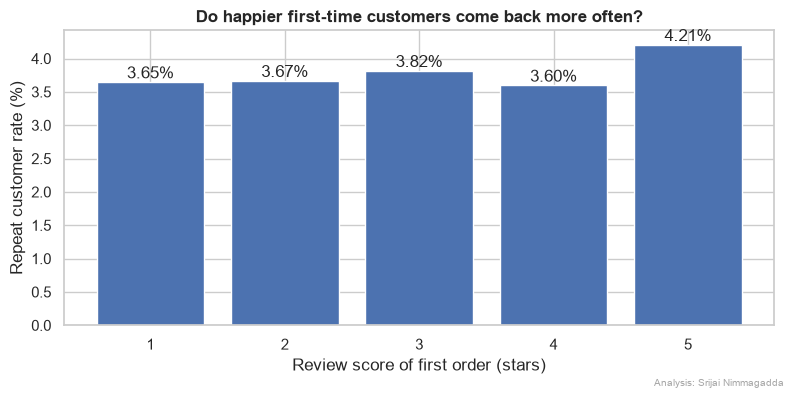

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(by_review.index.astype(int).astype(str), by_review["repeat_rate"], color="#4C72B0")
ax.bar_label(bars, fmt="%.2f%%")
ax.set_xlabel("Review score of first order (stars)")
ax.set_ylabel("Repeat customer rate (%)")
ax.set_title("Do happier first-time customers come back more often?", fontweight="bold")
plt.tight_layout()
plt.gcf().text(0.99, 0.01, "Analysis: Srijai Nimmagadda", ha="right", va="bottom", fontsize=7, color="gray", alpha=0.7)
plt.savefig(IMAGES / "05_repeat_by_first_review.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
master["order_month"] = master["order_purchase_timestamp"].dt.to_period("M")
master["cohort"] = master.groupby("customer_unique_id")["order_month"].transform("min")
master["months_since_first"] = (master["order_month"] - master["cohort"]).apply(lambda x: x.n)

cohort_counts = (master.groupby(["cohort", "months_since_first"])["customer_unique_id"]
                       .nunique().unstack(fill_value=0))
retention = cohort_counts.divide(cohort_counts[0], axis=0) * 100

retention = retention.loc["2017-01":"2018-02", 1:6]   # cohorts with 6+ months of follow-up, months 1–6
print("Average month-1 retention:", round(retention[1].mean(), 2), "%")
retention.round(2)

Average month-1 retention: 0.47 %


months_since_first,1,2,3,4,5,6
cohort,,,,,,
2017-01,0.28,0.28,0.14,0.42,0.14,0.42
2017-02,0.18,0.31,0.12,0.43,0.12,0.25
2017-03,0.44,0.36,0.40,0.36,0.16,0.16
2017-04,0.62,0.22,0.18,0.27,0.27,0.35
2017-05,0.46,0.46,0.29,0.29,0.32,0.41
2017-06,0.49,0.40,0.43,0.30,0.40,0.36
2017-07,0.53,0.35,0.24,0.29,0.21,0.32
2017-08,0.69,0.35,0.27,0.35,0.52,0.30
2017-09,0.70,0.55,0.27,0.45,0.22,0.22


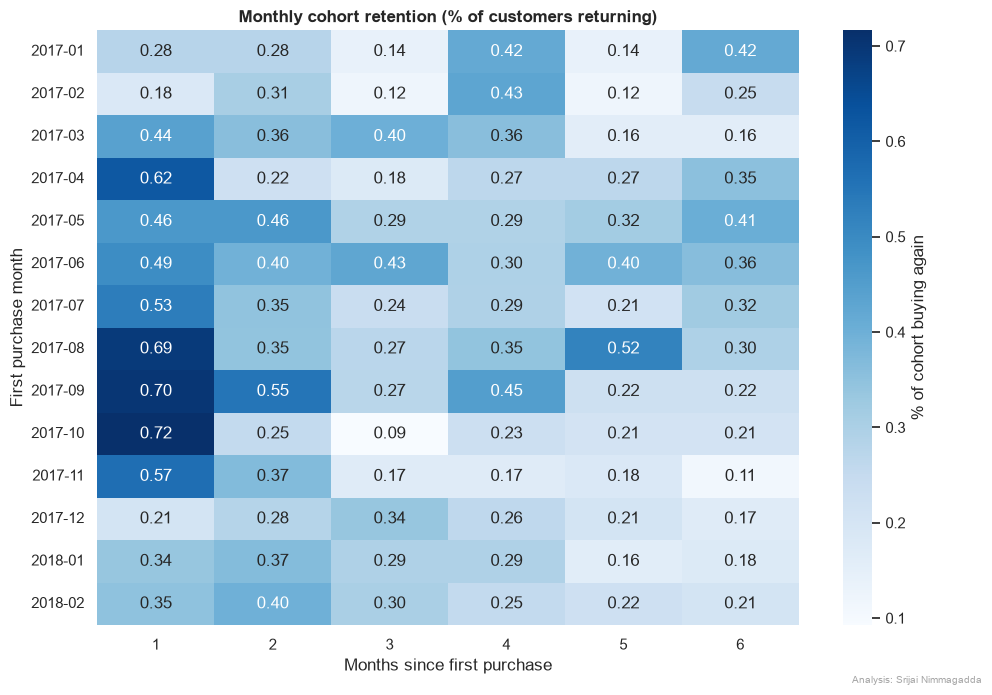

In [10]:
plt.figure(figsize=(10, 7))
sns.heatmap(retention, annot=True, fmt=".2f", cmap="Blues",
            cbar_kws={"label": "% of cohort buying again"})
plt.title("Monthly cohort retention (% of customers returning)", fontweight="bold")
plt.xlabel("Months since first purchase")
plt.ylabel("First purchase month")
plt.tight_layout()
plt.gcf().text(0.99, 0.01, "Analysis: Srijai Nimmagadda", ha="right", va="bottom", fontsize=7, color="gray", alpha=0.7)
plt.savefig(IMAGES / "06_cohort_retention.png", dpi=150, bbox_inches="tight")
plt.show()

## Key findings
1. **Late first deliveries reduce repeat purchases:** customers whose first order arrived late returned 3.05% of the time vs 4.04% for on-time first orders, about 25% fewer repeat customers (chi-square p = 0.0033).
2. **Only excellent experiences drive loyalty:** customers giving 1–4 stars on their first order return at similar rates (3.6–3.8%); only 5-star customers return noticeably more (4.21%).
3. **Retention is consistently low:** average month-1 retention is 0.47%, and no monthly cohort exceeds 0.72% in any month.
4. **Caveat:** these are associations, not proof of cause; late deliveries are concentrated in distant states, which may differ in other ways.

## Recommendations
- Treat on-time delivery of the **first order** as a retention priority, not only a logistics metric.
- Follow up quickly on late first orders (apology + discount on the next order) to recover at-risk new customers.
- Build a re-engagement programme (post-purchase emails, loyalty rewards), since customers currently have no reason to return.